Dataset link: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

# 1. Chargement des données

In [1]:
# installer TensorFlow
!pip install tensorflow

import tensorflow as tf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# vérifier la version de tensorflow
print(tf.__version__)

2.17.0


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

dataset = pd.read_csv("winequality.csv")

# 2. Analyse exploratoire (EDA)

In [4]:
dataset.head(10)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,white,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,white,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


In [5]:
# (nombre de lignes, nombre de colonnes)
dataset.shape

(6497, 13)

In [6]:
# des informations sur le jeu de données
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   object 
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [7]:
# lister les valeurs catégorielles
dataset.select_dtypes(include="object").columns

Index(['type'], dtype='object')

In [8]:
# la taille des valeurs catégorielles
len(dataset.select_dtypes(include="object").columns)

1

In [9]:
# lister les valeurs numeriques
dataset.select_dtypes(include="number").columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [10]:
# la taille des valeurs numériques
len(dataset.select_dtypes(include="number").columns)

12

In [11]:
# les statistiques
dataset.describe(include="all")

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497,6487.000000,6489.000000,6494.000000,6495.000000,6495.000000,6497.000000,6497.000000,6497.000000,6488.000000,6493.000000,6497.000000,6497.000000
unique,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,white,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,4898,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,7.216579,0.339691,0.318722,5.444326,0.056042,30.525319,115.744574,0.994697,3.218395,0.531215,10.491801,5.818378
std,NaN,1.296750,0.164649,0.145265,4.758125,0.035036,17.749400,56.521855,0.002999,0.160748,0.148814,1.192712,0.873255
min,NaN,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,NaN,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,NaN,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,NaN,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000


In [12]:
# lister totues les colonnes
dataset.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='object')

# 3. Gestion des valeurs manquantes

In [13]:
# vérifier si il existe des valeurs manquantes dans le jeu de données
dataset.isnull().values.any()

True

In [14]:
# le nombre de valeurs manquantes dans le jeu de données
dataset.isnull().values.sum()

38

In [15]:
# lister les valeurs manquantes
dataset.isna().sum()

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

# 4. Nettoyage des données

In [16]:
# remplacer les valeurs manquantes par la moyenne
dataset.fillna(dataset.mean(numeric_only=True), inplace=True)

In [17]:
# vérifier si il existe des valeurs manquantes dans le jeu de données
dataset.isnull().values.any()

False

In [18]:
# le nombre de valeurs manquantes dans le jeu de données
dataset.isnull().values.sum()

0

In [19]:
# lister les valeurs manquantes
dataset.isna().sum()

type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [20]:
dataset.head(10)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,white,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,white,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


# 5. Visualisation

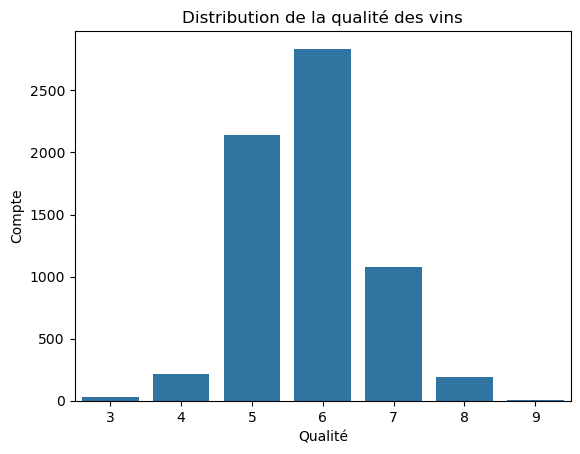

In [21]:
# Distribution cible
sns.countplot(x="quality", data=dataset)
plt.ylabel("Compte")
plt.xlabel("Qualité")
plt.title("Distribution de la qualité des vins")
plt.show()

In [22]:
# Distribution de la cible
dataset["quality"].value_counts()

quality
6    2836
5    2138
7    1079
4     216
8     193
3      30
9       5
Name: count, dtype: int64

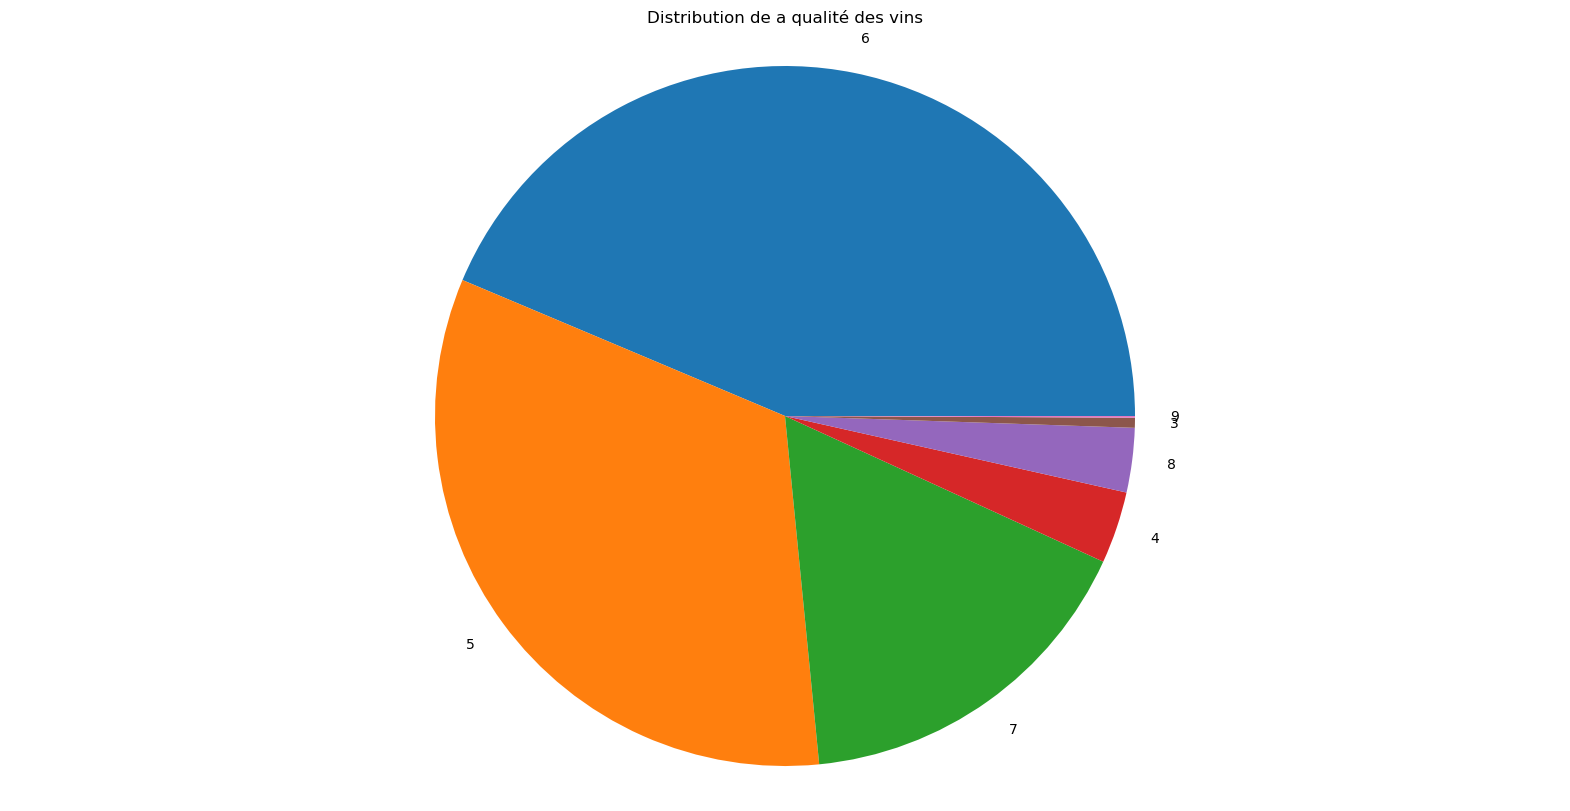

In [23]:
# Création d'un diagramme circulaire
plt.figure(figsize=(20, 10))
plt.pie(dataset["quality"].value_counts(), labels=dataset["quality"].value_counts().keys())
plt.title('Distribution de a qualité des vins')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [24]:
# Distribution du type
dataset["type"].value_counts()

type
white    4898
red      1599
Name: count, dtype: int64

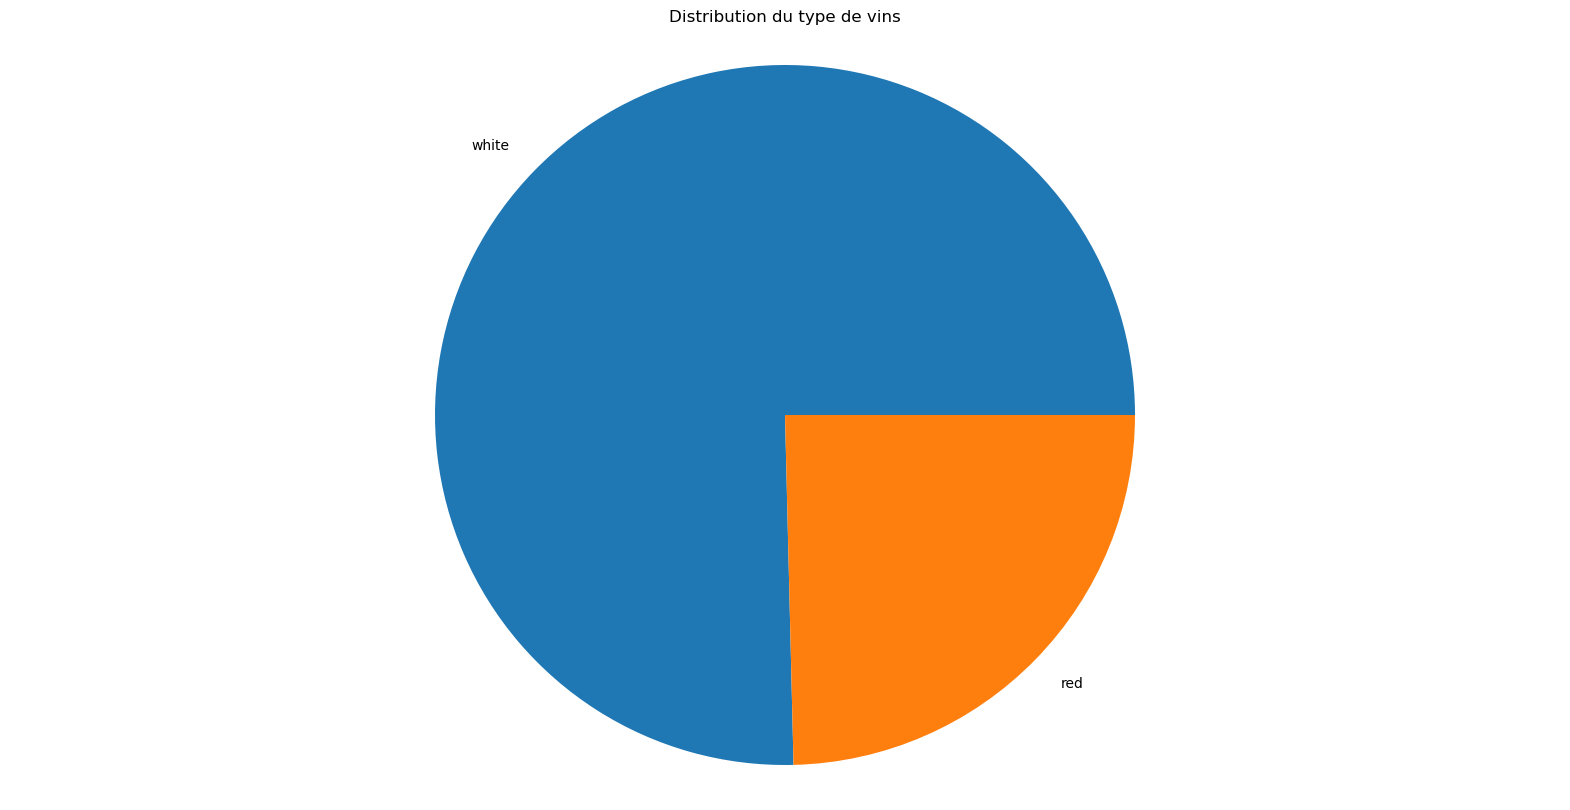

In [25]:
# Création d'un diagramme circulaire
plt.figure(figsize=(20, 10))
plt.pie(dataset["type"].value_counts(), labels=dataset["type"].value_counts().keys())
plt.title('Distribution du type de vins')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [26]:
# matrice de corrélation

# supprimer la variable cible (identifie)
dataset_2 = dataset.drop(columns="quality")

# selectionner les variables numériques
dataset_2 = dataset_2.select_dtypes(include=['number'])

# vérifier le jeu de données
dataset_2.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9


<Axes: title={'center': 'Corrélation avec qualité'}>

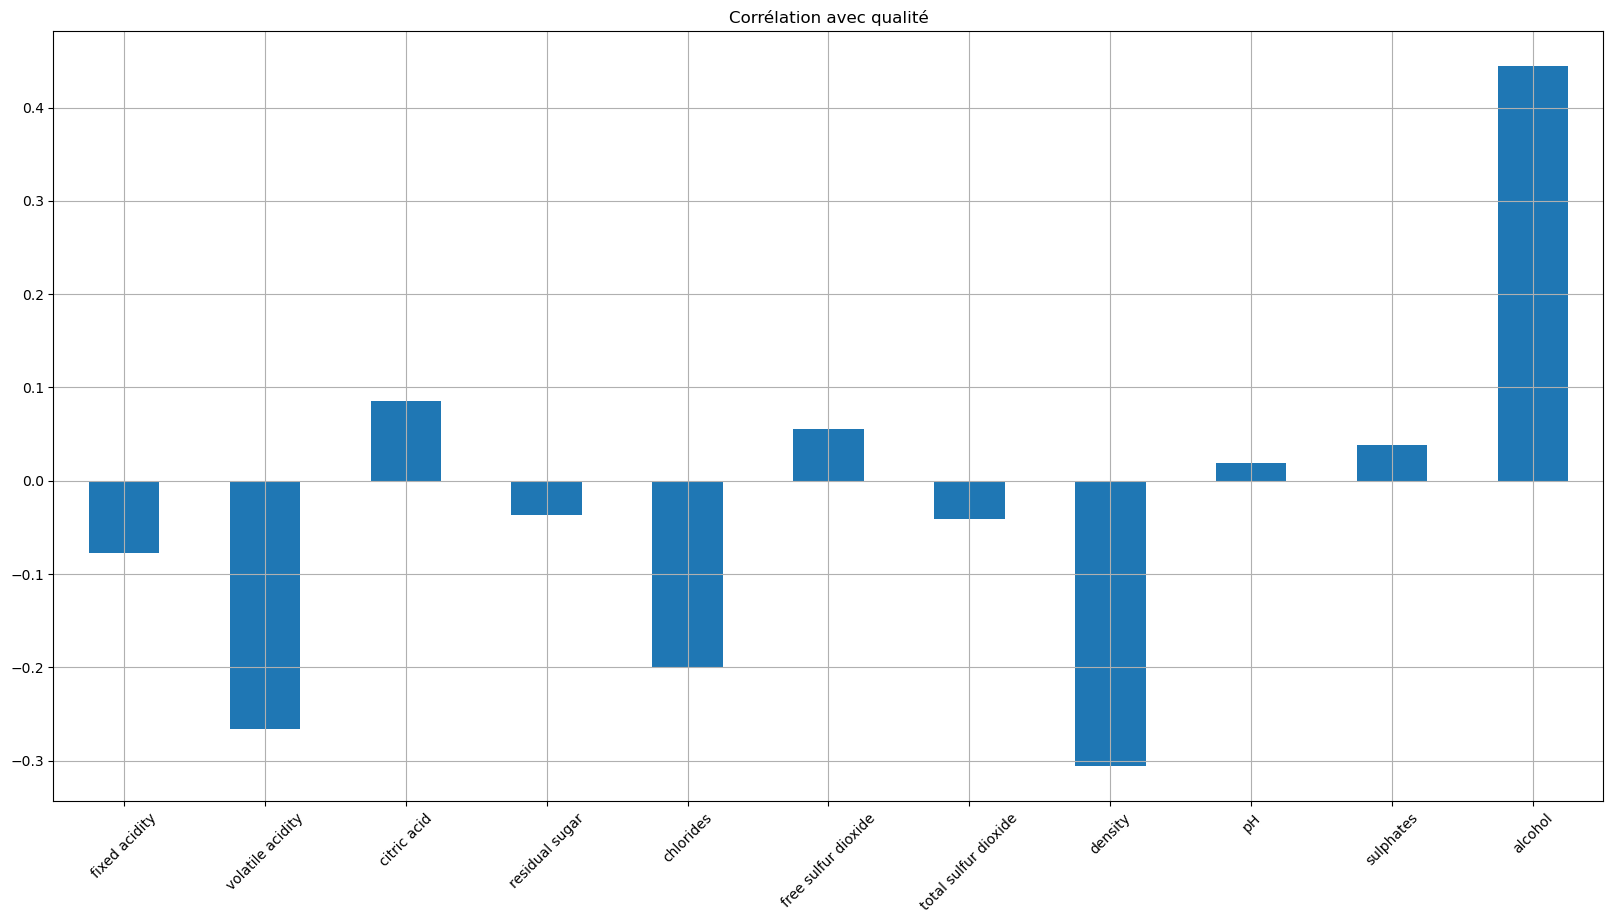

In [27]:
dataset_2.corrwith(dataset["quality"]).plot.bar(
    figsize=(20,10), title="Corrélation avec qualité", rot=45, grid=True
)

<Axes: >

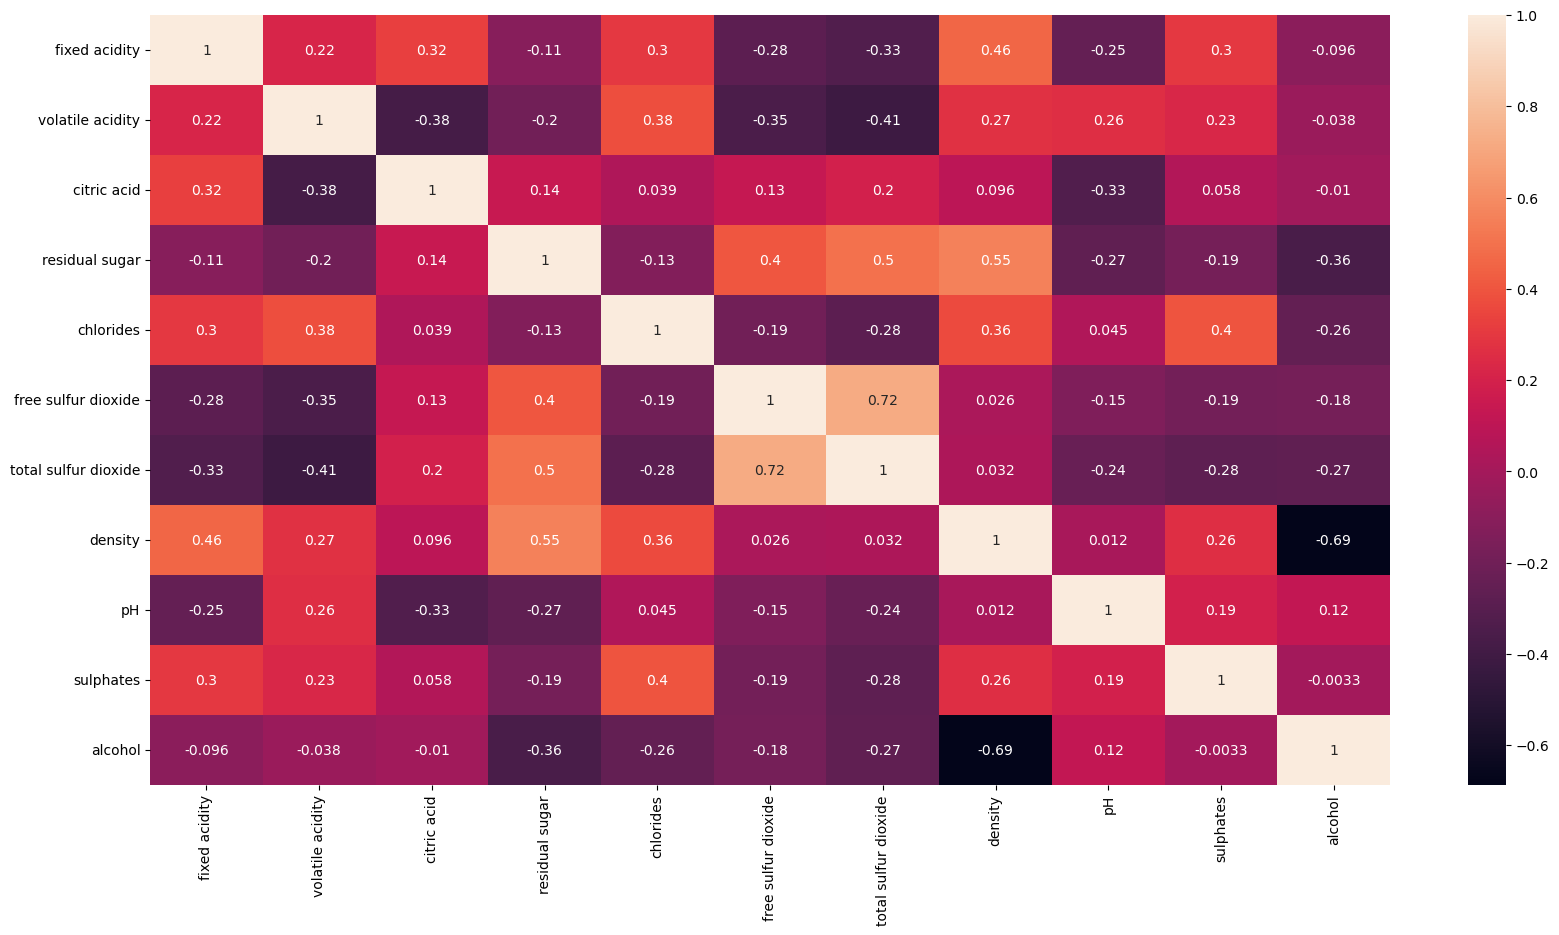

In [28]:
# heatmap
corr = dataset_2.corr()
plt.figure(figsize=(20,10))
sns.heatmap(corr, annot=True)

# 6. Préparation des données

In [29]:
# encoder les données catégorielles (one-hot encoding)
dataset = pd.get_dummies(data=dataset)

In [30]:
# Sélection des features
X = dataset.drop(["quality"], axis = 1)
y = dataset["quality"]

In [31]:
X.shape

(6497, 13)

In [32]:
y.shape

(6497,)

# 7. Train Test Split

In [33]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

print("Labels originaux :", encoder.classes_)
print("Labels encodés :", sorted(set(y_encoded)))

Labels originaux : [3 4 5 6 7 8 9]
Labels encodés : [0, 1, 2, 3, 4, 5, 6]


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5197, 13)
(1300, 13)
(5197,)
(1300,)


In [35]:
# Feature scaling (mettre toutes les variables à la même échelle)
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [36]:
X_train

array([[-0.47912182, -0.54359665,  0.27959341, ..., -1.08506915,
        -0.57312868,  0.57312868],
       [ 0.97474927, -1.08708507,  0.21065432, ..., -0.41405807,
        -0.57312868,  0.57312868],
       [-0.938239  , -0.36243385,  0.14171522, ..., -0.24630531,
        -0.57312868,  0.57312868],
       ...,
       [ 4.72420629, -0.42282145,  2.07200992, ..., -0.66568723,
         1.74480887, -1.74480887],
       [ 1.2808274 ,  0.36221738,  1.31367986, ...,  2.43773898,
         1.74480887, -1.74480887],
       [ 0.66867115, -0.42282145,  0.21065432, ..., -0.07855254,
        -0.57312868,  0.57312868]])

In [37]:
X_test

array([[-0.17304369, -0.54359665,  0.90004528, ...,  1.17959322,
        -0.57312868,  0.57312868],
       [ 0.28607349, -1.20786028,  2.89927908, ...,  0.256953  ,
        -0.57312868,  0.57312868],
       [-0.78519994, -1.14747268, -0.34085846, ..., -1.16894553,
        -0.57312868,  0.57312868],
       ...,
       [ 0.51563209, -0.12088344,  1.31367986, ..., -1.08506915,
         1.74480887, -1.74480887],
       [ 0.20955396,  1.14725621, -1.78857949, ...,  0.17307661,
         1.74480887, -1.74480887],
       [ 0.0565149 ,  1.026481  , -0.96131033, ..., -0.83343999,
         1.74480887, -1.74480887]])

# 8. Création du modèle de classification

In [38]:
input_dim = X_train.shape[1]
output_dim = len(encoder.classes_) 

# Définir un object
model = tf.keras.models.Sequential()

In [39]:
# Ajouter la première couche cachée (Couche Dense)
# 1) unités (Nombre de neurons) = 128
# 2) fonction d'activation = ReLU
# 3) input shape = 13

model.add(tf.keras.Input(shape=(input_dim,)))
model.add(tf.keras.layers.Dense(units=128, activation='relu'))

In [40]:
# Ajouter une deuxième couche avec dropout
model.add(tf.keras.layers.Dropout(0.3)) # drops 30% des neuron
# regularisation technique, pour éviter le surapprentissage (overfitting)

In [41]:
# Ajouter la couche output
# 1) unités = 1
# 2) activation = softmax
model.add(tf.keras.layers.Dense(units=output_dim, activation='softmax'))

In [42]:
# Compiler le modèle
# 1) Optimiseur = adam, (minimise la fonction de perte)
# 2) Fonction de perte = sparse_categorical_crossentropy, (pour guider l'optimiseur)
# 3) metrique = sparse_categorical_accuracy

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

In [43]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,695 (10.53 KB)

 Trainable params: 2,695 (10.53 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
# Entraîner le modèle
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    validation_split=0.2
)

Epoch 1/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.6653 - sparse_categorical_accuracy: 0.3226 - val_loss: 1.1761 - val_sparse_categorical_accuracy: 0.5317
Epoch 2/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1812 - sparse_categorical_accuracy: 0.5134 - val_loss: 1.1325 - val_sparse_categorical_accuracy: 0.5538
Epoch 3/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1384 - sparse_categorical_accuracy: 0.5239 - val_loss: 1.1070 - val_sparse_categorical_accuracy: 0.5529
Epoch 4/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1187 - sparse_categorical_accuracy: 0.5327 - val_loss: 1.0939 - val_sparse_categorical_accuracy: 0.5615
Epoch 5/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1194 - sparse_categorical_accuracy: 0.5335 - val_loss: 1.0943 - val_sparse_categorical_accuracy: 0.5538
Epoch 6/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0751 - sparse_categorical_accuracy: 0.5517 - val_loss: 1.0858 - val_sparse_categorical_accuracy: 0.5548
Epoc

In [45]:
def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    hist_data = pd.DataFrame(history.history)
    hist_data["epochs"] = range(1, len(hist_data) + 1)

    # Courbe de la loss
    sns.lineplot(data=hist_data, x="epochs", y="loss",
                 ax=axes[0], color="blue", label="Training Loss")
    sns.lineplot(data=hist_data, x="epochs", y="val_loss",
                 ax=axes[0], color="orange", label="Validation Loss")

    # Courbe de l'accuracy
    sns.lineplot(data=hist_data, x="epochs",
                 y="sparse_categorical_accuracy",
                 ax=axes[1], color="blue", label="Training Accuracy")
    sns.lineplot(data=hist_data, x="epochs",
                 y="val_sparse_categorical_accuracy",
                 ax=axes[1], color="orange", label="Validation Accuracy")

    axes[0].set_title("Model Loss")
    axes[1].set_title("Model Accuracy")

    plt.tight_layout()
    plt.show()

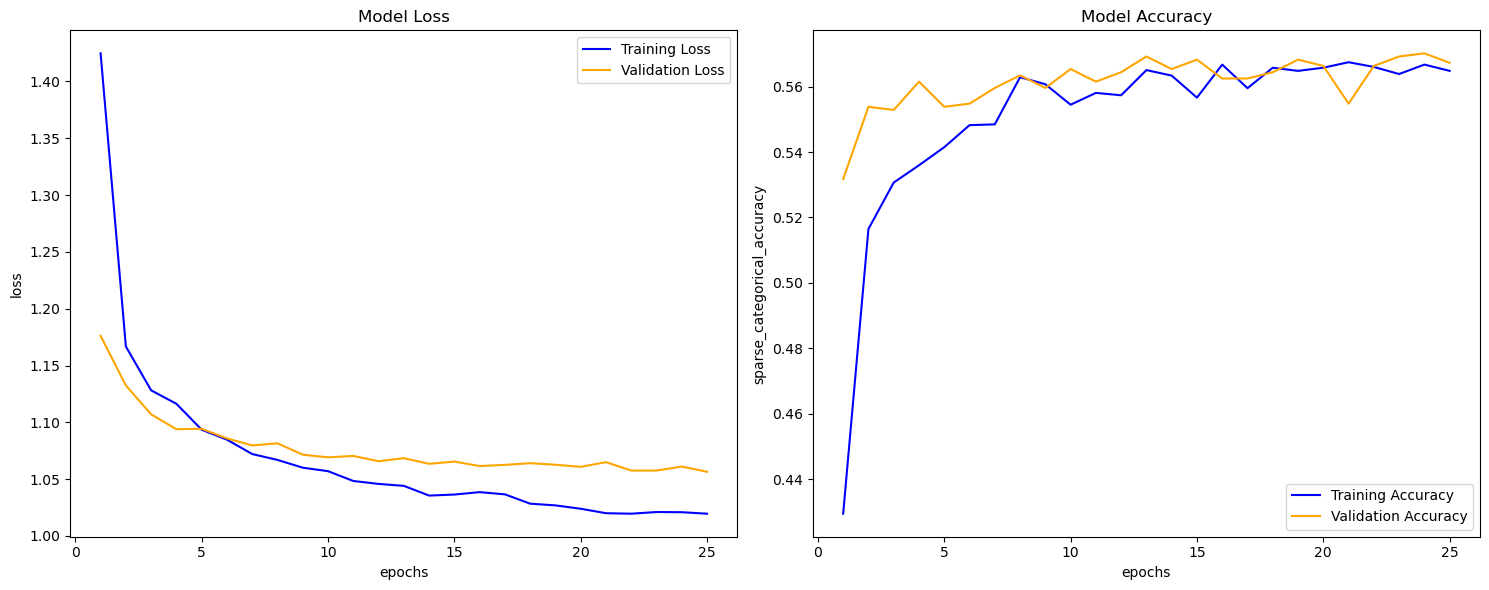

In [46]:
plot_history(history)

In [47]:
# Evaluation du modèle
test_loss, test_accuracy = model.evaluate(X_test, y_test)

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 956us/step - loss: 1.0076 - sparse_categorical_accuracy: 0.5398


In [48]:
print('Test Loss: {}'.format(test_loss))
print('Test Accuracy: {}'.format(test_accuracy))

Test Loss: 0.9898445010185242
Test Accuracy: 0.555384635925293


In [49]:
# Faire des prédictions
# model.predict(x_test) → retourne des probabilitiés
# np.argmax(..., axis=1) → selectionne les classes avec les plus hautes probabilités

y_pred = model.predict(X_test)
y_pred = np.argmax(y_pred, axis=1)

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [50]:
print(y_pred)

[4 3 3 ... 2 3 3]


In [51]:
# valeur prédite et valeur de test
y_pred[50],  y_test[50]

(3, 3)

In [52]:
# Matice de confusion
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[  0   0   2   0   0   0]
 [  0   5  28  13   0   0]
 [  0   3 280 135   2   0]
 [  0   0 147 366  66   0]
 [  0   0  12 138  71   0]
 [  0   0   0  13  19   0]]


In [53]:
acc_cm = accuracy_score(y_test, y_pred)
print('Accuracy Finale: {}'.format(acc_cm))

Accuracy Finale: 0.5553846153846154


# 9. Création du modèle de régression

In [54]:
# Définir un object
model_2 = tf.keras.models.Sequential()

In [55]:
# Ajouter la première couche cachée (Couche Dense)
# 1) unités (Nombre de neurons) = 128
# 2) fonction d'activation = ReLU
# 3) input shape = 13

model_2.add(tf.keras.Input(shape=(input_dim,)))
model_2.add(tf.keras.layers.Dense(units=128, activation='relu'))

In [56]:
# Ajouter une deuxième couche avec dropout

model_2.add(tf.keras.layers.Dropout(0.3)) # drops 30% des neuron
# regularisation technique, pour éviter le surapprentissage (overfitting)

In [57]:
# Ajouter la couche output
# 1) unités = 1
# 2) activation = linear

model_2.add(tf.keras.layers.Dense(units=1, activation='linear'))

In [58]:
# Compiler le modèle
# 1) Optimiseur = rmsprop, (minimise la fonction de perte)
# 2) Fonction de perte = mse, (pour guider l'optimiseur)
# 3) metriques = [MAE, MSE]

model_2.compile(optimizer='rmsprop',loss='mse', metrics=["mae", "mse"])

In [59]:
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,921 (7.50 KB)

 Trainable params: 1,921 (7.50 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# Entraîner le modèle
history_2 = model_2.fit(
    X_train,
    y_train,
    epochs=25,
    validation_split=0.2
)

Epoch 1/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 5.1716 - mae: 1.9408 - mse: 5.1716 - val_loss: 0.7670 - val_mae: 0.6763 - val_mse: 0.7670
Epoch 2/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8718 - mae: 0.7365 - mse: 0.8718 - val_loss: 0.6260 - val_mae: 0.6034 - val_mse: 0.6260
Epoch 3/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8180 - mae: 0.7041 - mse: 0.8180 - val_loss: 0.5900 - val_mae: 0.5873 - val_mse: 0.5900
Epoch 4/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6954 - mae: 0.6537 - mse: 0.6954 - val_loss: 0.5685 - val_mae: 0.5723 - val_mse: 0.5685
Epoch 5/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6829 - mae: 0.6460 - mse: 0.6829 - val_loss: 0.5417 - val_mae: 0.5612 - val_mse: 0.5417
Epoch 6/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6233 - mae: 0.6146 - mse: 0.6233 - val_loss: 0.5342 - val_mae: 0.5555 - val_mse: 0.5342
Epoch 7/25
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6199 - mae: 0.6125 - mse: 0.6199 - val

In [61]:
def plot_history_2(history):
    fig, axes = plt.subplots(1,2, figsize=(15,6))
    hist_data = history.history
    hist_data["epochs"] = list(range(1, len(history.history["loss"])+1))

    hist_data = pd.DataFrame(hist_data)
    sns.lineplot(data=hist_data, x="epochs", y="loss", ax=axes[0], color = "blue")
    sns.lineplot(data=hist_data, x="epochs", y="val_loss", ax=axes[0], color = "orange")

    sns.lineplot(data=hist_data, x="epochs", y="mae", ax=axes[1], color = "blue")
    sns.lineplot(data=hist_data, x="epochs", y="val_mae", ax=axes[1], color = "orange")

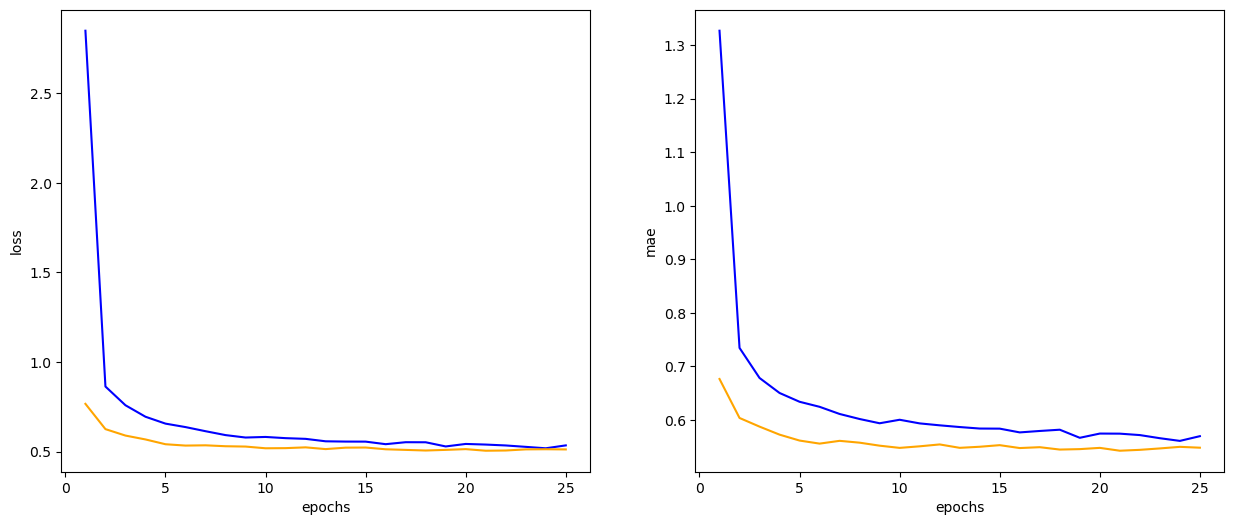

In [62]:
plot_history_2(history_2)

In [63]:
# Evaluation du modèle
y_pred = model_2.predict(X_test)

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [64]:
print('Test Loss: {}'.format(test_loss))
print('Test Accuracy: {}'.format(test_accuracy))

Test Loss: 0.9898445010185242
Test Accuracy: 0.555384635925293


In [65]:
# Faire des prédictions
# model.predict(x_test) → retourne des probabilitiés
# np.argmax(..., axis=1) → selectionne les classes avec les plus hautes probabilités

y_pred = np.argmax(y_pred, axis=1)

In [66]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mean_squared_error(y_pred, y_test)

8.67153846153846

In [67]:
# Le modèle a été entraîné à prédire des notes entre 0 et 10.
# On remultiplie les vecteur y_pred et y_test pour avoir une métrique interprétable
mean_absolute_error(y_pred*10, y_test*10)

28.20769230769231

In [68]:
# valeur prédite et valeur de test
y_pred[50],  y_test[50]

(0, 3)

In [69]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[  2   0   0   0   0   0]
 [ 46   0   0   0   0   0]
 [420   0   0   0   0   0]
 [579   0   0   0   0   0]
 [221   0   0   0   0   0]
 [ 32   0   0   0   0   0]]


# 10. Compatibilité avec un GridSearchCV

In [70]:
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV

In [71]:
def model_2(input_dim, activation, nb_hidden_layers,
            nb_units, optimizer, loss):

    model = tf.keras.models.Sequential()

    model.add(tf.keras.Input(shape=(input_dim,)))

    for i in range(nb_hidden_layers):
        model.add(
            tf.keras.layers.Dense(
                units=nb_units,
                activation=activation
            )
        )

    model.add(tf.keras.layers.Dense(1, activation="linear"))

    model.compile(
        optimizer=optimizer,
        loss=loss
    )

    return model

In [72]:
model_keras = KerasRegressor(
    model=model_2,
    epochs=10,
    verbose=0
)

In [73]:
hyperparameters = {
    "model__input_dim": [input_dim],
    "model__activation": ["relu", "sigmoid"],
    "model__nb_hidden_layers": [2, 3],
    "model__nb_units": [10, 20],
    "model__optimizer": ["rmsprop", "adam"],
    "model__loss": ["mse"]
}

In [74]:
grid = GridSearchCV(estimator=model_keras, param_grid=hyperparameters, cv=2)

In [75]:
grid.fit(X_train, y_train)

GridSearchCV(cv=2,
             estimator=KerasRegressor(epochs=10, model=<function model_2 at 0x00000261E1A0CA40>, verbose=0),
             param_grid={'model__activation': ['relu', 'sigmoid'],
                         'model__input_dim': [13], 'model__loss': ['mse'],
                         'model__nb_hidden_layers': [2, 3],
                         'model__nb_units': [10, 20],
                         'model__optimizer': ['rmsprop', 'adam']})

In [76]:
# Meilleurs hyperparamètres trouvés
best_params = grid.best_params_
print("Meilleurs paramètres :", best_params)

Meilleurs paramètres : {'model__activation': 'relu', 'model__input_dim': 13, 'model__loss': 'mse', 'model__nb_hidden_layers': 3, 'model__nb_units': 20, 'model__optimizer': 'rmsprop'}


In [77]:
# Meilleur estimateur (modèle)
best_model = grid.best_estimator_
print("Meilleur modèle :", best_model)

Meilleur modèle : KerasRegressor(
	model=<function model_2 at 0x00000261E1A0CA40>
	build_fn=None
	warm_start=False
	random_state=None
	optimizer=rmsprop
	loss=None
	metrics=None
	batch_size=None
	validation_batch_size=None
	verbose=0
	callbacks=None
	validation_split=0.0
	shuffle=True
	run_eagerly=False
	epochs=10
	model__activation=relu
	model__input_dim=13
	model__loss=mse
	model__nb_hidden_layers=3
	model__nb_units=20
	model__optimizer=rmsprop
)


In [78]:
# Meilleur score de validation croisée
best_score = grid.best_score_
print("Meilleur score :", best_score)

Meilleur score : 0.3071466316606537
